# Clasificación de orbitas

In [1]:
# Import libraries
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Load the data
DATA_PATH = Path("../data/raw/satellites_202602.csv")

In [2]:
def classify_orbit(row):
    period = row["PERIOD"]
    inc = row["INCLINATION"]
    apogee = row["APOGEE"]
    perigee = row["PERIGEE"]


    # GEO: geosincrónica, casi circular y ecuatorial
    if (
        not pd.isna(period)
        and not pd.isna(inc)
        and 1420 <= period <= 1450
        and abs(inc) <= 2
        and 35000 <= perigee <= 36500
        and 35000 <= apogee <= 36500
    ):
        return "GEO"

    # GSO: período geosincrónico, pero no necesariamente geoestacionaria
    if not pd.isna(period) and 1420 <= period <= 1450:
        return "GSO"

    # LEO: toda la órbita permanece por debajo de 2000 km
    if apogee < 2000:
        return "LEO"

    # MEO
    if (perigee < 2000 <= apogee) or (perigee >= 2000 and apogee < 35000):
        return "MEO"

    # Órbitas superiores a la región geoestacionaria
    if perigee > 36500:
        return "HEO"

    return "Unknown"

In [3]:
# Load the data from the CSV file
data = pd.read_csv(DATA_PATH)

# Classify the orbit for each satellite in the dataset
data["ORBIT_CLASS"] = data.apply(classify_orbit, axis=1)
data.head(10)

,INTLDES,NORAD_CAT_ID,OBJECT_TYPE,SATNAME,COUNTRY,LAUNCH,SITE,DECAY,PERIOD,INCLINATION,...,LAUNCH_YEAR,LAUNCH_NUM,LAUNCH_PIECE,CURRENT,OBJECT_NAME,OBJECT_ID,OBJECT_NUMBER,ACTIVE,PURPOSE,ORBIT_CLASS
0,1957-001B,2,PAYLOAD,SPUTNIK 1,CIS,1957-10-04,TTMTR,1958-01-03,96.10,65.00,...,1957,1,B,Y,SPUTNIK 1,1957-001B,2,No,Technology Development,LEO
1,1957-002A,3,PAYLOAD,SPUTNIK 2,CIS,1957-11-03,TTMTR,1958-04-14,103.74,65.33,...,1957,2,A,Y,SPUTNIK 2,1957-002A,3,No,Technology Development,LEO
2,1958-001A,4,PAYLOAD,EXPLORER 1,US,1958-02-01,AFETR,1970-03-31,88.48,33.15,...,1958,1,A,Y,EXPLORER 1,1958-001A,4,No,Technology Development,LEO
3,1958-002B,5,PAYLOAD,VANGUARD 1,US,1958-03-17,AFETR,NaN,132.60,34.25,...,1958,2,B,Y,VANGUARD 1,1958-002B,5,No,Technology Development,MEO
4,1958-002C,1576,DEBRIS,VANGUARD DEB,US,1958-03-17,AFETR,NaN,121.78,34.22,...,1958,2,C,Y,VANGUARD DEB,1958-002C,1576,No,NaN,MEO
5,1958-003A,6,PAYLOAD,EXPLORER 3,US,1958-03-26,AFETR,1958-06-28,151.74,19.24,...,1958,3,A,Y,EXPLORER 3,1958-003A,6,No,Technology Development,MEO
6,1958-004B,8,PAYLOAD,SPUTNIK 3,CIS,1958-05-15,TTMTR,1960-04-06,88.43,65.06,...,1958,4,B,Y,SPUTNIK 3,1958-004B,8,No,Technology Development,LEO
7,1958-005A,9,PAYLOAD,EXPLORER 4,US,1958-07-26,AFETR,1959-10-23,92.81,50.25,...,1958,5,A,Y,EXPLORER 4,1958-005A,9,No,Technology Development,LEO
8,1958-006A,10,PAYLOAD,SCORE,US,1958-12-18,AFETR,1959-01-21,98.21,32.29,...,1958,6,A,Y,SCORE,1958-006A,10,No,Technology Development,LEO
9,1958-007A,110,PAYLOAD,PIONEER 1,US,1958-10-11,AFETR,1958-10-12,NaN,NaN,...,1958,7,A,Y,PIONEER 1,1958-007A,110,No,Technology Development,Unknown


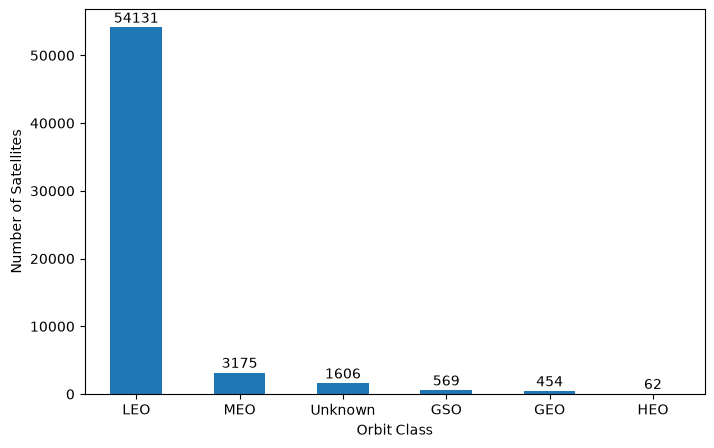

In [4]:
# Create a bar plot of the orbit class distribution with annotations
orbit_count = data["ORBIT_CLASS"].value_counts()
plt.figure(figsize=(8, 5))
ax = orbit_count.plot(kind='bar', rot=0)
ax.set_xlabel('Orbit Class')
ax.set_ylabel('Number of Satellites')

for rect in ax.patches:
    y_value = rect.get_height()
    x_value = rect.get_x() + rect.get_width() / 2
    space = 1
    label = "{:.0f}".format(y_value)
    ax.annotate(label, (x_value, y_value), xytext=(0, space), textcoords="offset points", ha='center', va='bottom')
plt.show()
